# Practice 1 – FashionMNIST: Data Pipeline & Phân tích dữ liệu

Notebook này làm **phần dữ liệu** theo đúng quy trình Data Pipeline (Chương 2, slide 15):

| Giai đoạn | Nội dung |
|---|---|
| **1. Data Collection** | Xác định bài toán → xác định dữ liệu cần → thu thập |
| **2. Data Preprocessing** | Kiểm tra định dạng, làm sạch, lấy mẫu / chia tập |
| **3. Data Transformation** | Chuẩn hóa (normalize), giảm chiều (PCA), đóng gói DataLoader |

Phần xây mô hình, training loop, đánh giá sẽ làm tiếp ở notebook sau, dùng lại `train_loader`, `val_loader`, `test_loader` tạo ở cuối notebook này.

## 0. Chuẩn bị môi trường

In [1]:
import random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu | Device: cpu


## 1. Data Collection

**Xác định bài toán:** phân loại ảnh (multi-class classification, 10 lớp) các món đồ thời trang.

**Dữ liệu cần:** ảnh đầu vào + nhãn lớp tương ứng (học có giám sát).

**Nguồn dữ liệu:** bộ **Fashion-MNIST** do Zalando Research công bố (cũng có trên Kaggle và GitHub `zalandoresearch/fashion-mnist`). Ở đây tải trực tiếp qua `torchvision.datasets.FashionMNIST` (tự động tải lần đầu, các lần sau dùng lại bản đã lưu trong `./data`).

Lúc này **chưa** truyền `transform`, để quan sát dữ liệu thô trước.

In [2]:
DATA_DIR = "./data"
raw_train = datasets.FashionMNIST(root=DATA_DIR, train=True,  download=True)
raw_test  = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)

CLASS_NAMES = raw_train.classes
print(CLASS_NAMES)

100.0%
100.0%
100.0%
100.0%

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 1.1 Tổng quan dữ liệu thô

In [3]:
X_train_raw = raw_train.data.numpy()      # (N, 28, 28), uint8
y_train     = raw_train.targets.numpy()
X_test_raw  = raw_test.data.numpy()
y_test      = raw_test.targets.numpy()

overview = pd.DataFrame({
    "tập":        ["train", "test"],
    "số mẫu":     [len(X_train_raw), len(X_test_raw)],
    "shape ảnh":  [X_train_raw.shape[1:], X_test_raw.shape[1:]],
    "dtype":      [X_train_raw.dtype, X_test_raw.dtype],
    "pixel min":  [X_train_raw.min(), X_test_raw.min()],
    "pixel max":  [X_train_raw.max(), X_test_raw.max()],
    "số lớp":     [len(np.unique(y_train)), len(np.unique(y_test))],
})
overview

,tập,số mẫu,shape ảnh,dtype,pixel min,pixel max,số lớp
0,train,60000,"(28, 28)",uint8,0,255,10
1,test,10000,"(28, 28)",uint8,0,255,10


## 2. Data Preprocessing

### 2.1 Làm sạch (Cleaning)
Kiểm tra: nhãn hợp lệ, ảnh trống, ảnh trùng lặp trong train, và **rò rỉ dữ liệu** (ảnh train xuất hiện lại trong test).
(Dữ liệu ảnh `uint8` nên không thể có giá trị NaN; chỉ cần kiểm tra khoảng giá trị 0–255 ở bảng trên.)

In [4]:
# Nhãn hợp lệ
assert set(np.unique(y_train)) == set(range(10)), "Nhãn train bất thường"
assert set(np.unique(y_test))  == set(range(10)), "Nhãn test bất thường"

# Ảnh trống (toàn pixel 0)
blank_train = int((X_train_raw.reshape(len(X_train_raw), -1).max(axis=1) == 0).sum())

# Ảnh trùng lặp + rò rỉ train/test
def img_hashes(X):
    return [hashlib.md5(x.tobytes()).hexdigest() for x in X]

h_train, h_test = img_hashes(X_train_raw), img_hashes(X_test_raw)
dup_train = len(h_train) - len(set(h_train))
leak      = len(set(h_train) & set(h_test))

print(f"Ảnh trống trong train        : {blank_train}")
print(f"Ảnh trùng lặp trong train    : {dup_train}")
print(f"Ảnh train xuất hiện ở test   : {leak}")

Ảnh trống trong train        : 0
Ảnh trùng lặp trong train    : 0
Ảnh train xuất hiện ở test   : 0


### 2.2 Phân bố lớp (Class distribution)
Dữ liệu có cân bằng không? Điều này quyết định có thể dùng **accuracy** hay cần thêm precision/recall/F1 (xem slide 14).

,label,class,train,test,train_%
0,0,T-shirt/top,6000,1000,10.0
1,1,Trouser,6000,1000,10.0
2,2,Pullover,6000,1000,10.0
3,3,Dress,6000,1000,10.0
4,4,Coat,6000,1000,10.0
5,5,Sandal,6000,1000,10.0
6,6,Shirt,6000,1000,10.0
7,7,Sneaker,6000,1000,10.0
8,8,Bag,6000,1000,10.0
9,9,Ankle boot,6000,1000,10.0


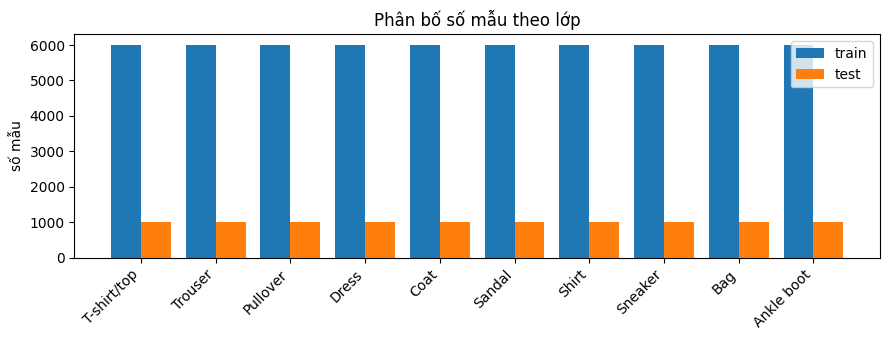

In [5]:
df_dist = pd.DataFrame({
    "label": range(10),
    "class": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=10),
    "test":  np.bincount(y_test,  minlength=10),
})
df_dist["train_%"] = (df_dist["train"] / len(y_train) * 100).round(2)
display(df_dist)

fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(10); w = 0.4
ax.bar(x - w/2, df_dist["train"], w, label="train")
ax.bar(x + w/2, df_dist["test"],  w, label="test")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("số mẫu"); ax.set_title("Phân bố số mẫu theo lớp"); ax.legend()
plt.tight_layout(); plt.show()

### 2.3 Quan sát trực quan mẫu dữ liệu

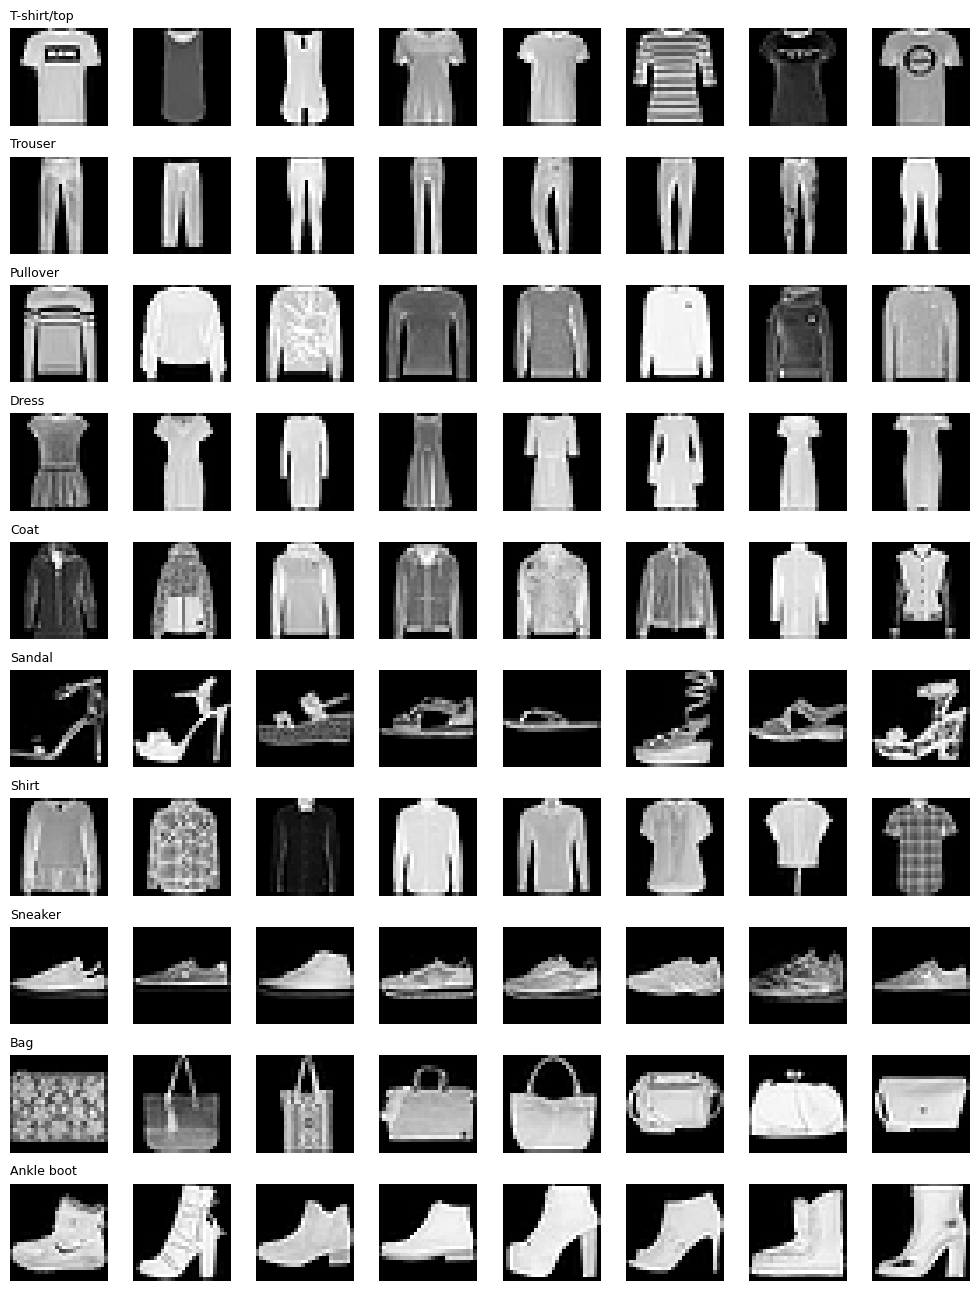

In [6]:
fig, axes = plt.subplots(10, 8, figsize=(10, 13))
for c in range(10):
    idx = np.where(y_train == c)[0][:8]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(X_train_raw[i], cmap="gray")
        ax.axis("off")
        if j == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=9, loc="left")
plt.tight_layout(); plt.show()

### 2.4 Ảnh trung bình của từng lớp

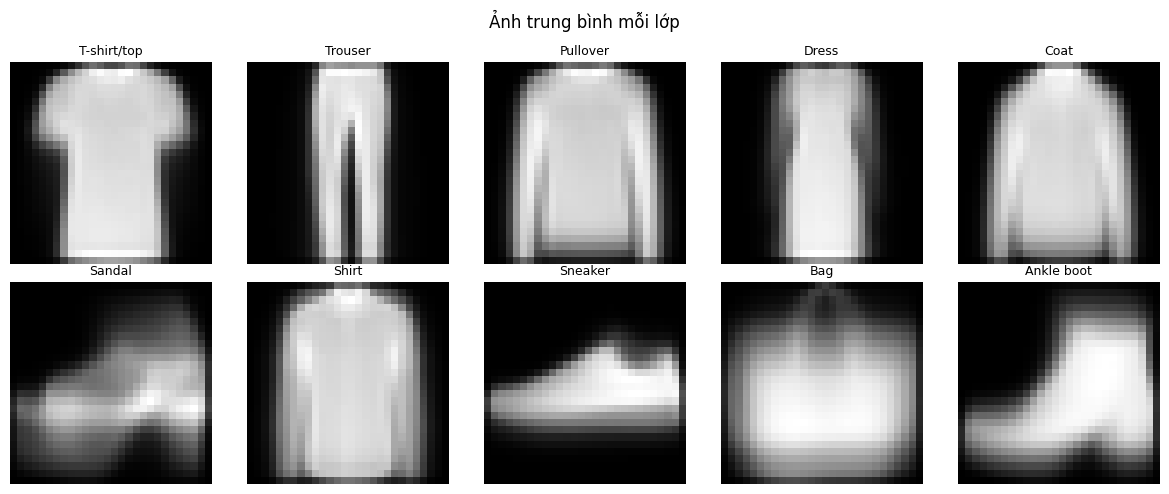

In [7]:
Xf = X_train_raw.astype(np.float32) / 255.0
class_means = np.stack([Xf[y_train == c].mean(axis=0) for c in range(10)])

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(class_means[c], cmap="gray"); ax.set_title(CLASS_NAMES[c], fontsize=9); ax.axis("off")
plt.suptitle("Ảnh trung bình mỗi lớp"); plt.tight_layout(); plt.show()

### 2.5 Thống kê cường độ pixel

Mean toàn bộ (0-1): 0.2860
Std  toàn bộ (0-1): 0.3530
Tỉ lệ pixel = 0   : 50.21%


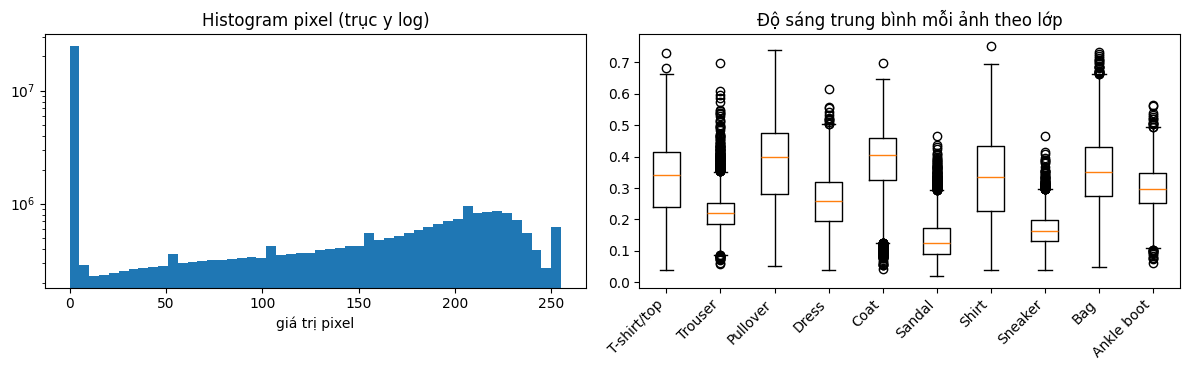

In [8]:
print(f"Mean toàn bộ (0-1): {Xf.mean():.4f}")
print(f"Std  toàn bộ (0-1): {Xf.std():.4f}")
print(f"Tỉ lệ pixel = 0   : {(X_train_raw == 0).mean()*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(X_train_raw.ravel(), bins=50, log=True)
axes[0].set_title("Histogram pixel (trục y log)"); axes[0].set_xlabel("giá trị pixel")

brightness = Xf.mean(axis=(1, 2))   # độ sáng trung bình từng ảnh
axes[1].boxplot([brightness[y_train == c] for c in range(10)])
axes[1].set_xticks(range(1, 11)); axes[1].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
axes[1].set_title("Độ sáng trung bình mỗi ảnh theo lớp")

plt.tight_layout(); plt.show()

### 2.6 Mức độ giống nhau giữa các lớp
Khoảng cách Euclid giữa các ảnh trung bình: cặp lớp nào **gần nhau** thì mô hình dễ nhầm lẫn. Có thể dùng để giải thích confusion matrix ở bước đánh giá.

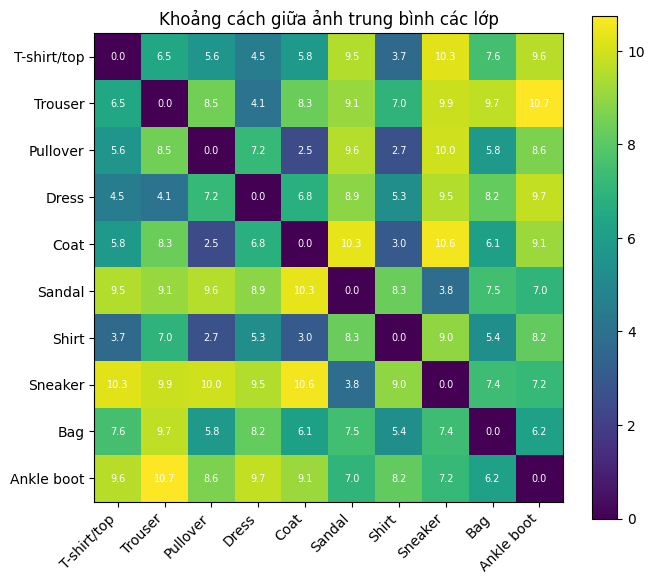

5 cặp lớp giống nhau nhất:
  Pullover     - Coat        : 2.48
  Pullover     - Shirt       : 2.68
  Coat         - Shirt       : 3.02
  T-shirt/top  - Shirt       : 3.72
  Sandal       - Sneaker     : 3.84


In [9]:
flat = class_means.reshape(10, -1)
dist = np.linalg.norm(flat[:, None, :] - flat[None, :, :], axis=2)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(dist, cmap="viridis")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{dist[i, j]:.1f}", ha="center", va="center", color="w", fontsize=7)
plt.colorbar(im); ax.set_title("Khoảng cách giữa ảnh trung bình các lớp")
plt.tight_layout(); plt.show()

pairs = sorted((dist[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(i + 1, 10))
print("5 cặp lớp giống nhau nhất:")
for d, a, b in pairs[:5]:
    print(f"  {a:12s} - {b:12s}: {d:.2f}")

## 3. Data Transformation

### 3.1 Giảm chiều bằng PCA (Decomposition)
Mỗi ảnh có 784 chiều. PCA giúp xem cấu trúc dữ liệu: cần bao nhiêu thành phần để giữ phần lớn thông tin, và các lớp có tách nhau trong không gian 2D không. (Chỉ để phân tích, **không** dùng PCA làm đầu vào cho mạng.)

50 thành phần giữ 86.3% phương sai


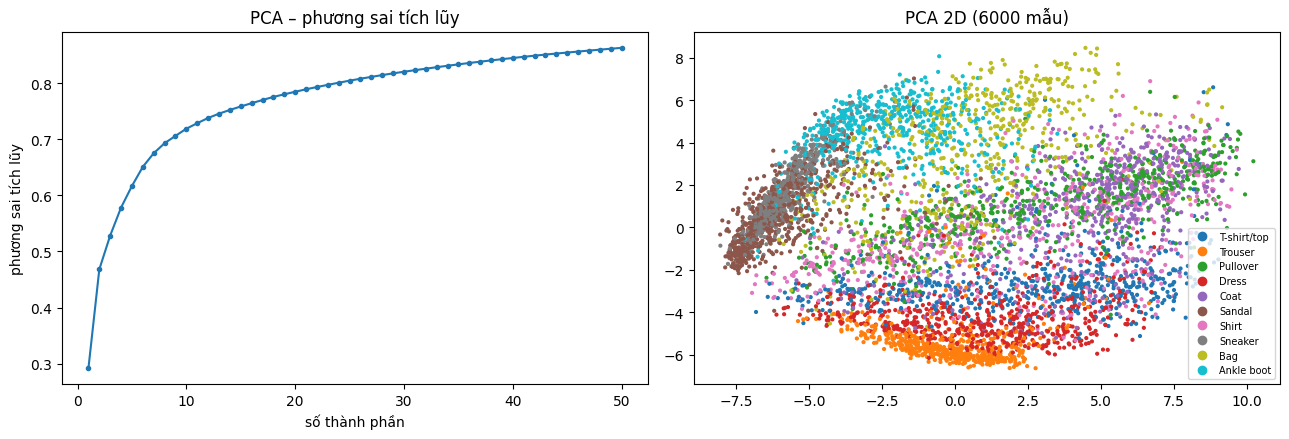

In [10]:
from sklearn.decomposition import PCA

rng = np.random.default_rng(SEED)
sub = rng.choice(len(Xf), size=6000, replace=False)
X_sub = Xf[sub].reshape(len(sub), -1)
y_sub = y_train[sub]

pca = PCA(n_components=50, random_state=SEED).fit(X_sub)
cum = np.cumsum(pca.explained_variance_ratio_)
print(f"Số thành phần để giữ 90% phương sai: {np.argmax(cum >= 0.90) + 1}" if cum[-1] >= 0.90
      else f"50 thành phần giữ {cum[-1]*100:.1f}% phương sai")

Z = pca.transform(X_sub)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, 51), cum, marker="o", ms=3)
axes[0].set_xlabel("số thành phần"); axes[0].set_ylabel("phương sai tích lũy"); axes[0].set_title("PCA – phương sai tích lũy")
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=y_sub, cmap="tab10", s=4)
axes[1].legend(sc.legend_elements()[0], CLASS_NAMES, fontsize=7, loc="best")
axes[1].set_title("PCA 2D (6000 mẫu)")
plt.tight_layout(); plt.show()

### 3.2 Chia tập Train / Validation / Test
- **Train:** 50.000 ảnh (học).
- **Validation:** 10.000 ảnh (chọn hyperparameter, phát hiện overfitting).
- **Test:** 10.000 ảnh gốc (đánh giá cuối cùng, **không đụng tới** khi tuning).

In [11]:
N_VAL = 10000
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(raw_train), generator=g)
val_idx, train_idx = perm[:N_VAL].tolist(), perm[N_VAL:].tolist()

split_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": np.bincount(y_train[train_idx], minlength=10),
    "val":   np.bincount(y_train[val_idx],   minlength=10),
})
print(f"train={len(train_idx)}, val={len(val_idx)}, test={len(raw_test)}")
split_df

train=50000, val=10000, test=10000


,class,train,val
0,T-shirt/top,5020,980
1,Trouser,5021,979
2,Pullover,4939,1061
3,Dress,5026,974
4,Coat,4954,1046
5,Sandal,4945,1055
6,Shirt,5016,984
7,Sneaker,5007,993
8,Bag,5043,957
9,Ankle boot,5029,971


### 3.3 Chuẩn hóa (Normalization)
Tính `mean` và `std` **chỉ trên tập train** (tránh rò rỉ thông tin từ val/test), rồi áp dụng cho cả ba tập:

$$x' = \frac{x - \mu}{\sigma}$$

In [12]:
train_pixels = torch.from_numpy(Xf[train_idx])
MEAN, STD = train_pixels.mean().item(), train_pixels.std().item()
print(f"MEAN = {MEAN:.4f} | STD = {STD:.4f}")

transform = transforms.Compose([
    transforms.ToTensor(),                  # uint8 [0,255] -> float [0,1], shape (1,28,28)
    transforms.Normalize((MEAN,), (STD,)),  # -> mean ~ 0, std ~ 1
])

full_train = datasets.FashionMNIST(DATA_DIR, train=True,  download=False, transform=transform)
test_ds    = datasets.FashionMNIST(DATA_DIR, train=False, download=False, transform=transform)
train_ds, val_ds = Subset(full_train, train_idx), Subset(full_train, val_idx)

MEAN = 0.2859 | STD = 0.3529


### 3.4 Đóng gói DataLoader

In [13]:
BATCH_SIZE = 128
pin = device.type == "cuda"

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=pin)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

images, labels = next(iter(train_loader))
print("Batch ảnh :", images.shape, images.dtype)
print("Batch nhãn:", labels.shape, labels.dtype)
print(f"Sau chuẩn hóa: mean={images.mean():.3f}, std={images.std():.3f}, min={images.min():.2f}, max={images.max():.2f}")

Batch ảnh : torch.Size([128, 1, 28, 28]) torch.float32
Batch nhãn: torch.Size([128]) torch.int64
Sau chuẩn hóa: mean=-0.070, std=0.964, min=-0.81, max=2.02


### 3.5 Kiểm tra lại sau biến đổi (trước vs sau chuẩn hóa)

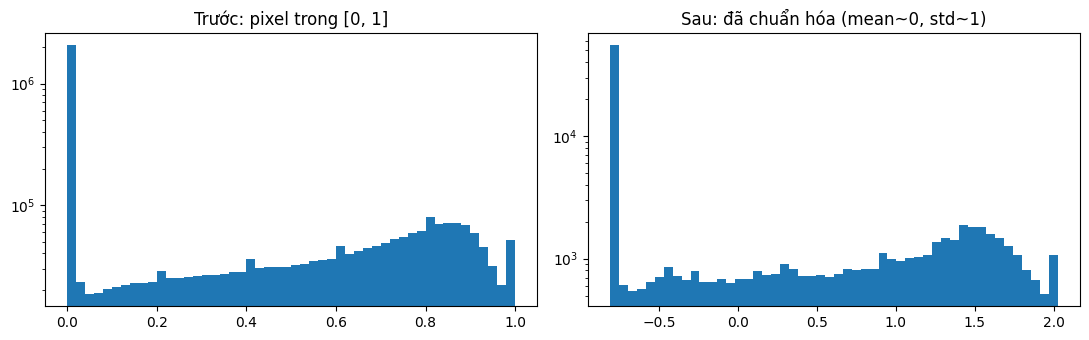

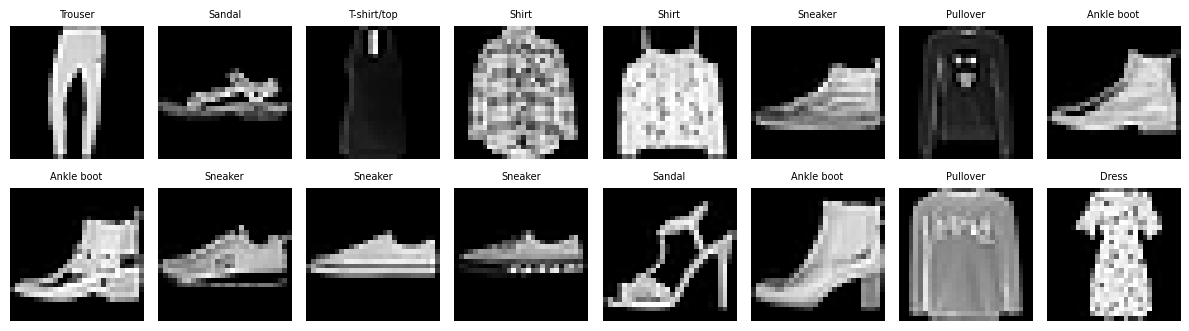

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(Xf[train_idx[:5000]].ravel(), bins=50, log=True); axes[0].set_title("Trước: pixel trong [0, 1]")
axes[1].hist(images.numpy().ravel(), bins=50, log=True);        axes[1].set_title("Sau: đã chuẩn hóa (mean~0, std~1)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lab in zip(axes.ravel(), images[:16], labels[:16]):
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(CLASS_NAMES[lab], fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Tổng kết Data Pipeline

| Bước | Việc đã làm | Kết quả |
|---|---|---|
| Collection | Tải FashionMNIST qua torchvision | 60.000 train + 10.000 test, ảnh xám 28×28, 10 lớp |
| Cleaning | Kiểm tra nhãn, ảnh trống, trùng lặp, rò rỉ | xem số liệu mục 2.1 |
| EDA | Phân bố lớp, ảnh mẫu, ảnh trung bình, histogram pixel, độ giống giữa các lớp | xem mục 2.2 – 2.6 |
| Decomposition | PCA | số thành phần cần thiết, mức độ tách lớp |
| Sampling | Chia 50.000 / 10.000 / 10.000 | train / val / test |
| Normalization | z-score với mean, std của tập train | mean≈0, std≈1 |
| Loading | DataLoader batch 128 | sẵn sàng cho training loop |

### Gợi ý ý để viết nhận xét trong báo cáo
- Dữ liệu **cân bằng** hay không (số mẫu mỗi lớp ở mục 2.2) → vì vậy dùng accuracy có hợp lý không.
- Những lớp **dễ nhầm** (cặp gần nhau ở mục 2.6, thường là nhóm áo: T-shirt, Shirt, Pullover, Coat) → đối chiếu với confusion matrix sau khi train.
- Số thành phần PCA cần để giữ 90% phương sai cho thấy dữ liệu **dư thừa** nhiều (784 chiều nhưng thông tin nằm trong không gian thấp hơn nhiều).
- Giải thích vì sao chuẩn hóa chỉ dùng thống kê của tập train (tránh data leakage).
- Nên đối chiếu `MEAN`, `STD` bạn tính được với giá trị thường gặp của FashionMNIST (khoảng 0.286 và 0.353).

# PHẦN 2 – HUẤN LUYỆN VÀ ĐÁNH GIÁ (DÙNG CHUNG SOURCE CODE)

**Nguyên tắc đồng bộ:** Notebook này không tự định nghĩa lại kiến trúc MLP/CNN hoặc hàm `fit()`. Toàn bộ training phải chạy qua `src.train`; đánh giá test phải chạy qua `src.evaluate`. Như vậy notebook, CLI và báo cáo sử dụng cùng model, data split, optimizer, early stopping và checkpoint.

- MLP: `configs/mlp.yaml`
- CNN: `configs/cnn.yaml`
- Mặc định không train lại để tránh vô tình ghi đè kết quả. Đổi `RUN_TRAINING = True` nếu muốn chạy lại cả hai mô hình.

In [ ]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
CONFIGS = {
    "MLP": "configs/mlp.yaml",
    "CNN": "configs/cnn.yaml",
}
RUN_TRAINING = False  # Đổi thành True để train + evaluate lại bằng đúng src/*.py

if RUN_TRAINING:
    for model_name, config_path in CONFIGS.items():
        print(f"===== TRAIN {model_name} =====")
        subprocess.run(
            [sys.executable, "-m", "src.train", "--config", config_path],
            cwd=ROOT, check=True
        )
        print(f"===== EVALUATE {model_name} =====")
        subprocess.run(
            [sys.executable, "-m", "src.evaluate", "--config", config_path],
            cwd=ROOT, check=True
        )
else:
    print("Đang đọc kết quả đã lưu. Đặt RUN_TRAINING=True nếu muốn chạy lại.")

## 5. Kết quả thực nghiệm từ pipeline chính

Các số liệu bên dưới được đọc trực tiếp từ `reports/mlp` và `reports/cnn`, không nhập lại thủ công. Nếu chạy lại training, hãy chạy lại cell này để cập nhật bảng và biểu đồ.

In [ ]:
def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

rows = []
histories = {}
for model_name, folder in [("MLP", "mlp"), ("CNN", "cnn")]:
    base = ROOT / "reports" / folder
    train_summary = read_json(base / "train_summary.json")
    metrics = read_json(base / "test_metrics.json")
    histories[model_name] = read_json(base / "history.json")
    rows.append({
        "Model": model_name,
        "Best validation accuracy": train_summary["best_val_acc"],
        "Test accuracy": metrics["test_accuracy"],
        "Macro-F1": metrics["test_macro_f1"],
        "Test loss": metrics["test_loss"],
        "Epochs": train_summary["epochs_run"],
        "Train time (s)": train_summary["train_time_s"],
        "Parameters": metrics["params_total"],
        "Latency (ms/image)": metrics["latency_ms_per_image"],
    })

results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.style.format({
    "Best validation accuracy": "{:.2%}",
    "Test accuracy": "{:.2%}",
    "Macro-F1": "{:.2%}",
    "Test loss": "{:.4f}",
    "Train time (s)": "{:.2f}",
    "Latency (ms/image)": "{:.4f}",
    "Parameters": "{:,.0f}",
}))

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
metrics_to_plot = [
    ("train_loss", "val_loss", "Loss"),
    ("train_acc", "val_acc", "Accuracy"),
]
for row, (train_key, val_key, title) in enumerate(metrics_to_plot):
    for model_name, hist in histories.items():
        epochs = range(1, len(hist[train_key]) + 1)
        axes[row, 0].plot(epochs, hist[train_key], marker="o", label=model_name)
        axes[row, 1].plot(epochs, hist[val_key], marker="o", label=model_name)
    axes[row, 0].set_title(f"Train {title}")
    axes[row, 1].set_title(f"Validation {title}")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 0].legend()
    axes[row, 1].legend()
plt.tight_layout()
plt.show()

## 6. Confusion Matrix và phân tích lỗi

Trong ma trận, **hàng là nhãn thực tế**, **cột là nhãn dự đoán**. Các phần tử trên đường chéo là dự đoán đúng; ngoài đường chéo là các trường hợp nhầm lẫn. Hình được tạo bởi `src.evaluate` từ checkpoint hiện tại.

In [ ]:
for model_name, folder in [("MLP", "mlp"), ("CNN", "cnn")]:
    print(f"Confusion Matrix – {model_name}")
    display(Image(filename=str(ROOT / "reports" / folder / "confusion_matrix.png"), width=760))

## 7. Lưu, nạp và dự đoán

Checkpoint được tạo bởi `src.train` và chứa `state_dict`, cấu hình mô hình, mean/std chuẩn hóa và tên lớp. Không tạo checkpoint MLP/CNN độc lập trong notebook nữa.

Ví dụ dự đoán một ảnh mới bằng checkpoint CNN:

```powershell
python -m src.predict --image path/to/image.png --checkpoint reports/cnn/fashion_mnist_cnn.pth
```

## 8. Checklist Practice 1

| Yêu cầu | Vị trí |
|---|---|
| Load FashionMNIST, khám phá dữ liệu | Mục 1–2 |
| Cleaning, class distribution, trực quan ảnh | Mục 2 |
| PCA, chia tập, normalization, DataLoader | Mục 3 |
| Xây dựng MLP/CNN | `src/model.py` |
| Forward, loss, backward, optimizer, validation | `src/train.py` |
| Accuracy, Precision, Recall, F1, Confusion Matrix | `src/evaluate.py` |
| Save/load checkpoint và dự đoán ảnh | `src/train.py`, `src/predict.py` |
| Loss curves và ảnh dự đoán | `reports/mlp/`, `reports/cnn/` |

**Lưu ý:** không dùng các kết quả huấn luyện cũ từng được tạo trực tiếp trong notebook để thay thế số liệu trong `reports/mlp` và `reports/cnn`. Source code trong `src/` cùng các file kết quả tương ứng là nguồn chuẩn cho báo cáo.